Self-Attention 마스터 클래스!

문장 분석: 'The cat sat on the mat'
Self-Attention 단계별 분해!
1단계: 단어 → 벡터 변환
  The: [-1.1182016134262085, -0.43220648169517517, -0.5030885338783264, 0.7244083881378174, -0.44709616899490356] ... (512차원)
  cat: [1.312751293182373, 0.3208550214767456, -2.310048818588257, 0.22563520073890686, -0.6838054060935974] ... (512차원)
  sat: [0.24212081730365753, -0.623552680015564, 1.7041908502578735, 0.5616208910942078, 1.1930238008499146] ... (512차원)
  on: [-1.1454105377197266, -0.5313302874565125, -0.40314775705337524, -2.041928291320801, -0.0038574791979044676] ... (512차원)
  the: [-0.756410539150238, -1.34865403175354, 0.09095199406147003, 1.5508177280426025, 1.045861840248108] ... (512차원)
  mat: [0.448101282119751, 0.6395841240882874, -1.0822948217391968, 1.4582767486572266, 2.390465497970581] ... (512차원)

2단계: Query, Key, Value 생성
  Q(Query): torch.Size([6, 512]) ─각 단어의 '질문' 벡터
  K(Key): torch.Size([6, 512]) ─각 단어의 '특성' 벡터
  V(Value): torch.Size([6, 512]) ─각 단어의 '정보' 벡터

3

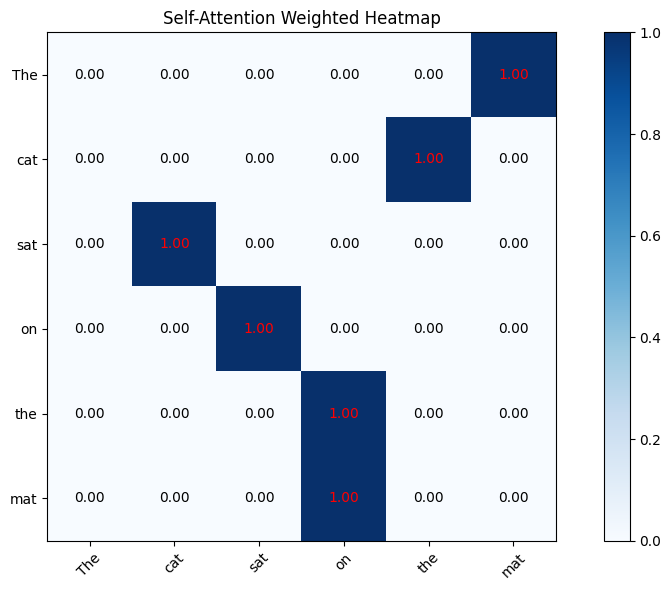


5단계: 맥락 정보 통합
  최종 출력: torch.Size([6, 512])

결과 해석:
  'The'는 'mat'와 가장 관련 (점수: 1.000)
  'cat'는 'the'와 가장 관련 (점수: 1.000)
  'sat'는 'cat'와 가장 관련 (점수: 1.000)
  'on'는 'sat'와 가장 관련 (점수: 1.000)
  'the'는 'on'와 가장 관련 (점수: 1.000)
  'mat'는 'on'와 가장 관련 (점수: 1.000)
------------------------------------------------------------

문장 분석: 'AI learns to understand language'
Self-Attention 단계별 분해!
1단계: 단어 → 벡터 변환
  AI: [0.3567313253879547, 2.3340280055999756, -0.10558898746967316, 0.8741006851196289, -0.45795825123786926] ... (512차원)
  learns: [-1.3046514987945557, 0.7646820545196533, -0.7203717827796936, 0.8381891846656799, 0.4459938108921051] ... (512차원)
  to: [1.4448453187942505, -0.8099011778831482, 1.0845458507537842, -0.034181587398052216, 0.6432788372039795] ... (512차원)
  understand: [0.48423686623573303, -0.6633560657501221, -1.9965535402297974, 0.607035756111145, 1.6036021709442139] ... (512차원)
  language: [-0.06430154293775558, 0.8571463823318481, 0.5622345805168152, -0.5059100389480591, -0.1061

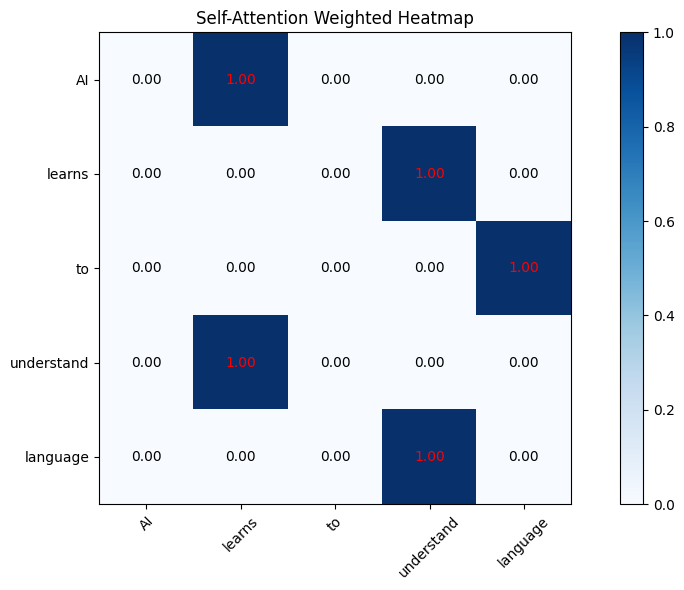


5단계: 맥락 정보 통합
  최종 출력: torch.Size([5, 512])

결과 해석:
  'AI'는 'learns'와 가장 관련 (점수: 1.000)
  'learns'는 'understand'와 가장 관련 (점수: 1.000)
  'to'는 'language'와 가장 관련 (점수: 1.000)
  'understand'는 'learns'와 가장 관련 (점수: 1.000)
  'language'는 'understand'와 가장 관련 (점수: 1.000)
------------------------------------------------------------

문장 분석: 'Transformer models revolutionized NLP'
Self-Attention 단계별 분해!
1단계: 단어 → 벡터 변환
  Transformer: [3.3408336639404297, 0.41204243898391724, -0.06689894944429398, -0.5995229482650757, 0.2140052616596222] ... (512차원)
  models: [-0.3707295358181, 1.2910847663879395, -0.382125586271286, 1.1000425815582275, 1.435767650604248] ... (512차원)
  revolutionized: [-0.5344492793083191, 1.1259913444519043, -0.15386812388896942, -1.8676393032073975, 1.660781979560852] ... (512차원)
  NLP: [0.162079319357872, -0.49169301986694336, -0.8669690489768982, -1.0854809284210205, 1.4485180377960205] ... (512차원)

2단계: Query, Key, Value 생성
  Q(Query): torch.Size([4, 512]) ─각 단어의 '질문' 벡터
  K(Key

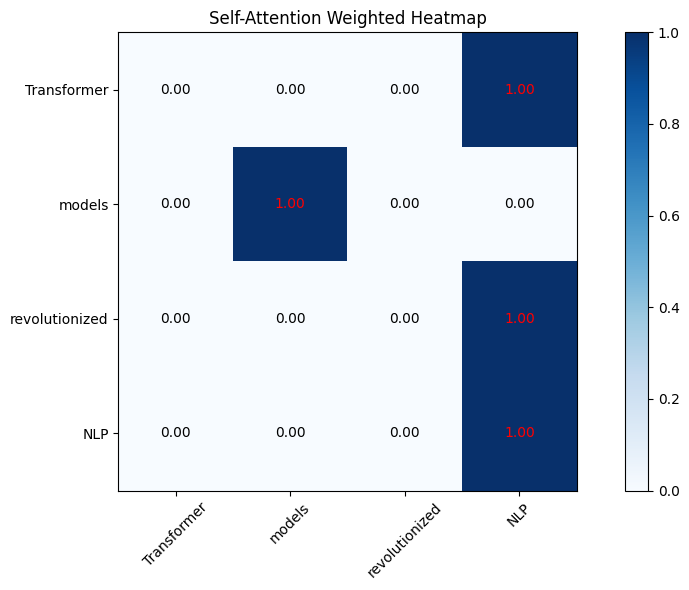


5단계: 맥락 정보 통합
  최종 출력: torch.Size([4, 512])

결과 해석:
  'Transformer'는 'NLP'와 가장 관련 (점수: 1.000)
  'models'는 'models'와 가장 관련 (점수: 1.000)
  'revolutionized'는 'NLP'와 가장 관련 (점수: 1.000)
  'NLP'는 'NLP'와 가장 관련 (점수: 1.000)
------------------------------------------------------------
실무 예제: 텍스트 감정 분석
입력 shape: torch.Size([2, 10, 512])
Attention 출력: torch.Size([2, 10, 512])
어텐션 가중치 shape: torch.Size([2, 10, 10])
감정 예측 결과: torch.Size([2, 3])
0: 부정, 1: 중립, 2: 긍정

Self-Attention 기본 구조 & 작동 파악 완료
다음 단계: HuggingFace Transformers로 실제 모델 사용하기


In [ ]:
### 7-1-1. Implementation of a full Self-Attention Model

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

class SelfAttentionExplainer:
  # Self-Attention을 직관적으로 이해하는 구조

  def __init__(self, d_model=512):
    # 임베딩 차원 = 512
    self.d_model = d_model

  def step_by_step_attention(self, sentence):
    # 단계별 Self-Attention 계산 과정 시연
    print("Self-Attention 단계별 분해!")
    print("=" * 50)

    words = sentence.split()
    vocab_size = len(words)

    # 1단계: 단어를 벡터로 변환(임베딩)
    print("1단계: 단어 → 벡터 변환")
    # 임베딩 행렬 크기 = (단어 수, 임베딩 차원)
    embeddings = torch.randn(vocab_size, self.d_model)
    for i, word in enumerate(words): # words에 포함된 인덱스&내용 동시 추출
      print(f"  {word}: {embeddings[i][:5].tolist()} ... (512차원)")

    # 2단계: Q, K, V 행렬 생성
    print("\n2단계: Query, Key, Value 생성")
    # 임의의 가중치 행렬 for Query, Key, Value 벡터
    W_q = torch.randn(self.d_model, self.d_model)
    W_k = torch.randn(self.d_model, self.d_model)
    W_v = torch.randn(self.d_model, self.d_model)

    # remind: @ 연산자 → 행렬 곱셈
    Q = embeddings @ W_q # Query 벡터: "누구와 관련 있나?"
    K = embeddings @ W_k # Key 벡터: "나의 특성은?"
    V = embeddings @ W_v # Value 벡터: "나의 실제 정보"

    print(f"  Q(Query): {Q.shape} ─각 단어의 '질문' 벡터")
    print(f"  K(Key): {K.shape} ─각 단어의 '특성' 벡터")
    print(f"  V(Value): {V.shape} ─각 단어의 '정보' 벡터")

    # 3단계: Attention Score 계산
    print("\n3단계: 관련도 점수 계산")
    scores = Q @ K.T / np.sqrt(self.d_model) # 스케일링
    print(f"  점수 행렬: {scores.shape}")

    # 4단계: Softmax로 확률 변환
    print("\n4단계: 확률로 변환")
    attention_weights = F.softmax(scores, dim=-1)
    # remind: 한 쿼리 벡터 당 확률 합계 1(=100%)

    # 시각화
    plt.figure(figsize=(10, 6))
    plt.imshow(attention_weights.detach().numpy(), cmap='Blues')
    plt.xticks(range(len(words)), words, rotation=45)
    plt.yticks(range(len(words)), words)
    plt.title('Self-Attention Weighted Heatmap')
    plt.colorbar()

    # 수치 표시
    for i in range(len(words)):
      for j in range(len(words)):
        plt.text(j, i, f'{attention_weights[i,j]:.2f}',
                 ha='center', va='center', color='red'
                 if attention_weights[i,j] > 0.3 else 'black')

    plt.tight_layout()
    plt.show()

    # 5단계 최종 출력 계산
    print("\n5단계: 맥락 정보 통합")
    output = attention_weights @ V
    print(f"  최종 출력: {output.shape}")

    # 해석
    print("\n결과 해석:")
    for i, word in enumerate(words):
      top_attention = torch.argmax(attention_weights[i])
      top_word = words[top_attention] # 가장 확률 높은 단어 선택
      top_score = attention_weights[i, top_attention].item()
      print(f"  '{word}'는 '{top_word}'와 가장 관련 (점수: {top_score:.3f})")

    return output, attention_weights


# 실제 사용 예제
def run_attention_demo():
  # Self-Attention 데모 실행
  explainer = SelfAttentionExplainer()

  # 예제 문장
  sentences = ["The cat sat on the mat",
              "AI learns to understand language",
              "Transformer models revolutionized NLP"

  ]

  for sentence in sentences:
    print(f"\n문장 분석: '{sentence}'")
    output, weights = explainer.step_by_step_attention(sentence)
    print("-" * 60)


# 실제 파이토치 Multi-Head Attention 사용법
class PracticalAttentionExample:
  # Multi-Head Attention

  def __init__(self):
    self.multihead_attn = nn.MultiheadAttention(
        embed_dim=512, num_heads=8, batch_first=True
    )

  def text_classification_with_attention(self):
    # 텍스트 분류에 Attention 적용 예제
    print("실무 예제: 텍스트 감정 분석")

    # 가상의 텍스트 데이터(배치 크기=2, 시퀀스 길이=10, 임베딩=512)
    batch_size, seq_len, embed_dim = 2, 10, 512
    text_embeddings = torch.randn(batch_size, seq_len, embed_dim)

    # Multi-Head Attention 적용
    attn_output, attn_weights = self.multihead_attn(
        text_embeddings, text_embeddings, text_embeddings
    )

    print(f"입력 shape: {text_embeddings.shape}")
    print(f"Attention 출력: {attn_output.shape}")
    print(f"어텐션 가중치 shape: {attn_weights.shape}")

    # 감정 분류를 위한 간단한 분류기
    classifier = nn.Sequential(
        nn.Linear(embed_dim, 256),
        nn.ReLU(),
        nn.Dropout(0.1),
        nn.Linear(256, 3) # 긍정, 부정, 중립
    )

    # 시퀀스의 평균 사용(간단한 풀링)
    pooled = attn_output.mean(dim=1) # [batch_size, embed_dim]
    predictions = classifier(pooled) # [batch_size, 3]

    print(f"감정 예측 결과: {predictions.shape}")
    print("0: 부정, 1: 중립, 2: 긍정")

    return predictions


# 실행
print("Self-Attention 마스터 클래스!")
print("=" * 50)

# 1. 기본 이해
run_attention_demo()

# 2. 실무 적용

practical = PracticalAttentionExample()
practical.text_classification_with_attention()

print("\nSelf-Attention 기본 구조 & 작동 파악 완료")
print("다음 단계: HuggingFace Transformers로 실제 모델 사용하기")

# remind: 이 코드에서 사용한 Multi-head Attention 모델은 아직 학습 X
# 즉 가중치 히트맵이 예상과 다를 확률이 높다. (눈 감고 다트를 던진 것과 같다.)

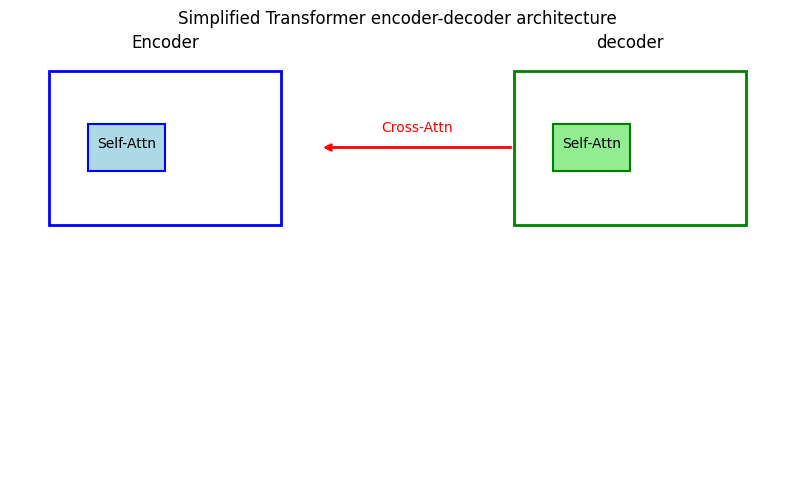

In [ ]:
### 7-1-2. Visualization of Encoder-Decoder Structures with Matplotlib

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)

# 인코더 블록
encoder = Rectangle((0.5, 3.5), 3, 2, edgecolor='blue', facecolor='none',lw=2)
ax.add_patch(encoder)
ax.text(2, 5.8, 'Encoder', horizontalalignment='center', fontsize=12)


# 디코더 블록
decoder = Rectangle((6.5, 3.5), 3, 2, edgecolor='green', facecolor='none',lw=2)
ax.add_patch(decoder)
ax.text(8, 5.8, 'decoder', horizontalalignment='center', fontsize=12)


# Self-Attention(인코더 내부)
encoder_sa = Rectangle((1, 4.2), 1, 0.6, edgecolor='blue',
                       facecolor='lightblue',lw=1.5)
ax.add_patch(encoder_sa)
ax.text(1.5, 4.5, 'Self-Attn', horizontalalignment='center', fontsize=10)


# Self-Attention(el코더 내부)
decoder_sa = Rectangle((7, 4.2), 1, 0.6, edgecolor='green',
                       facecolor='lightgreen',lw=1.5)
ax.add_patch(decoder_sa)
ax.text(7.5, 4.5, 'Self-Attn', horizontalalignment='center', fontsize=10)

# 인코더-디코더 Attention(크로스-Attention)
ax.annotate("", xy=(4, 4.5), xytext=(6.5, 4.5),
            arrowprops=dict(arrowstyle="->", lw=2, color='red'))
ax.text(5.25, 4.7, 'Cross-Attn', horizontalalignment='center',
        color='red', fontsize=10)

ax.axis('off')
plt.title('Simplified Transformer encoder-decoder architecture')
plt.show()